# Comparative Analysis of News Classification Models
### Inshort News Dataset | Google Colab

**Models:** Multinomial Naive Bayes, Logistic Regression, Linear SVM, K-Nearest Neighbors, Random Forest, XGBoost, and LSTM.

**Evaluation:** Accuracy, weighted precision/recall/F1, macro-F1, training/prediction time, classification reports, and confusion matrices.




In [ ]:
# 1. Install/import libraries
!pip -q install xgboost

import os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42


In [ ]:
# 2. Upload and load the dataset
uploaded = files.upload()  # Select inshort_news_data-1.csv
csv_name = next(iter(uploaded.keys()))
df = pd.read_csv(csv_name)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
print("\\nMissing values:\\n", df.isnull().sum())
print("\\nCategory distribution:\\n", df["news_category"].value_counts())


Saving inshort_news_data-1.csv to inshort_news_data-1.csv
Dataset shape: (4817, 4)
Columns: ['Unnamed: 0', 'news_headline', 'news_article', 'news_category']


,Unnamed: 0,news_headline,news_article,news_category
0,0,50-year-old problem of biology solved by Artif...,DeepMind's AI system 'AlphaFold' has been reco...,technology
1,1,Microsoft Teams to stop working on Internet Ex...,Microsoft Teams will stop working on Internet ...,technology
2,2,Hope US won't erect barriers to cooperation: C...,"China, in response to reports of US adding Chi...",technology
3,3,Global smartphone sales in Q3 falls 5.7% to 36...,The global smartphone sales in the third quart...,technology
4,4,EU hoping Biden will clarify US position on di...,The European Union (EU) is hoping that US Pres...,technology


\nMissing values:\n Unnamed: 0       0
news_headline    0
news_article     0
news_category    0
dtype: int64
\nCategory distribution:\n news_category
world            1021
entertainment     998
sports            856
technology        751
politics          546
science           389
automobile        256
Name: count, dtype: int64


In [ ]:
# 3. Clean and prepare the data
required_cols = ["news_headline", "news_article", "news_category"]
df = df.dropna(subset=required_cols).copy()

# Combine headline and article so all models use the same text input
df["text"] = (
    df["news_headline"].astype(str).str.strip() + " " +
    df["news_article"].astype(str).str.strip()
).str.replace(r"\\s+", " ", regex=True).str.strip()

df = df[df["text"].str.len() > 0].reset_index(drop=True)

X = df["text"]
y_text = df["news_category"].astype(str)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
class_names = label_encoder.classes_

print("Number of samples:", len(df))
print("Classes:", list(class_names))
print("Class counts:")
display(df["news_category"].value_counts().rename_axis("category").reset_index(name="count"))


Number of samples: 4817
Classes: ['automobile', 'entertainment', 'politics', 'science', 'sports', 'technology', 'world']
Class counts:


,category,count
0,world,1021
1,entertainment,998
2,sports,856
3,technology,751
4,politics,546
5,science,389
6,automobile,256


In [ ]:
# 4. Train-test split (stratified; identical split for all models)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 3853
Testing samples: 964


## Part A — Classical Machine Learning

TF-IDF converts text into numeric features. Each pipeline fits its vectorizer on the training text only, preventing test-set leakage. The same split is used for all classical models.

In [ ]:
# 5. Define classical ML models
# Use sparse TF-IDF features for text classification.
models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english", ngram_range=(1, 2),
            max_features=50000, min_df=2, sublinear_tf=True
        )),
        ("model", MultinomialNB(alpha=0.5))
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english", ngram_range=(1, 2),
            max_features=50000, min_df=2, sublinear_tf=True
        )),
        ("model", LogisticRegression(
            max_iter=2000, class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english", ngram_range=(1, 2),
            max_features=50000, min_df=2, sublinear_tf=True
        )),
        ("model", LinearSVC(
            class_weight="balanced", random_state=RANDOM_STATE
        ))
    ]),
    "KNN (cosine)": Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english", ngram_range=(1, 2),
            max_features=30000, min_df=2, sublinear_tf=True
        )),
        ("model", KNeighborsClassifier(
            n_neighbors=5, metric="cosine", algorithm="brute", n_jobs=-1
        ))
    ]),
    "Random Forest": Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english", ngram_range=(1, 2),
            max_features=30000, min_df=2, sublinear_tf=True
        )),
        ("model", RandomForestClassifier(
            n_estimators=250, max_depth=None,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

# Optional additional algorithm
from xgboost import XGBClassifier
models["XGBoost"] = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english", ngram_range=(1, 2),
        max_features=30000, min_df=2, sublinear_tf=True
    )),
    ("model", XGBClassifier(
        n_estimators=250, max_depth=6, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.8,
        objective="multi:softmax", num_class=len(class_names),
        eval_metric="mlogloss", tree_method="hist",
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])


In [ ]:
# 6. Train and evaluate all classical models
results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    print(f"Training {name} ...")
    start_train = time.time()
    model.fit(X_train, y_train)
    train_seconds = time.time() - start_train

    start_pred = time.time()
    y_pred = model.predict(X_test)
    pred_seconds = time.time() - start_pred

    trained_models[name] = model
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1_weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "Training_time_sec": train_seconds,
        "Prediction_time_sec": pred_seconds
    })

    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f} | Macro-F1: {f1_score(y_test, y_pred, average='macro'):.4f}")
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))


Training Multinomial Naive Bayes ...
Accuracy: 0.9015 | Macro-F1: 0.8784
               precision    recall  f1-score   support

   automobile       0.92      0.65      0.76        51
entertainment       0.96      0.95      0.96       200
     politics       0.97      0.98      0.98       109
      science       0.87      0.71      0.78        78
       sports       0.98      0.96      0.97       171
   technology       0.81      0.84      0.82       150
        world       0.83      0.94      0.88       205

     accuracy                           0.90       964
    macro avg       0.91      0.86      0.88       964
 weighted avg       0.90      0.90      0.90       964

Training Logistic Regression ...
Accuracy: 0.9367 | Macro-F1: 0.9332
               precision    recall  f1-score   support

   automobile       0.89      0.94      0.91        51
entertainment       0.97      0.94      0.95       200
     politics       0.97      1.00      0.99       109
      science       0.86     

## Part B — Deep Learning (LSTM)

The LSTM model uses integer token sequences and an embedding layer. Run this section after the classical models. In Colab, select **Runtime → Change runtime type → T4 GPU** for faster training (CPU also works but may take longer).

In [ ]:
# 7. Prepare sequences for LSTM
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(RANDOM_STATE)

MAX_WORDS = 30000
MAX_LEN = 250

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(train_sequences, maxlen=MAX_LEN, padding="post", truncating="post")
X_test_pad = pad_sequences(test_sequences, maxlen=MAX_LEN, padding="post", truncating="post")

print("Padded train shape:", X_train_pad.shape)
print("Padded test shape:", X_test_pad.shape)


Padded train shape: (3853, 250)
Padded test shape: (964, 250)


In [ ]:
# 8. Build, train, and evaluate LSTM
lstm_model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=128, mask_zero=True),
    Bidirectional(LSTM(64, dropout=0.2, recurrent_dropout=0.0)),
    Dense(64, activation="relu"),
    Dropout(0.4),
    Dense(len(class_names), activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss", patience=2,
    restore_best_weights=True
)

start_train = time.time()
history = lstm_model.fit(
    X_train_pad, y_train,
    validation_split=0.15,
    epochs=10,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)
lstm_train_seconds = time.time() - start_train

start_pred = time.time()
lstm_prob = lstm_model.predict(X_test_pad, verbose=0)
lstm_pred = np.argmax(lstm_prob, axis=1)
lstm_pred_seconds = time.time() - start_pred

predictions["BiLSTM"] = lstm_pred
results.append({
    "Model": "BiLSTM",
    "Accuracy": accuracy_score(y_test, lstm_pred),
    "Precision_macro": precision_score(y_test, lstm_pred, average="macro", zero_division=0),
    "Recall_macro": recall_score(y_test, lstm_pred, average="macro", zero_division=0),
    "F1_macro": f1_score(y_test, lstm_pred, average="macro", zero_division=0),
    "F1_weighted": f1_score(y_test, lstm_pred, average="weighted", zero_division=0),
    "Training_time_sec": lstm_train_seconds,
    "Prediction_time_sec": lstm_pred_seconds
})

print(classification_report(y_test, lstm_pred, target_names=class_names, zero_division=0))


Epoch 1/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 52s 453ms/step - accuracy: 0.3902 - loss: 1.5320 - val_accuracy: 0.7803 - val_loss: 0.6035
Epoch 2/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 45s 439ms/step - accuracy: 0.8650 - loss: 0.4341 - val_accuracy: 0.8979 - val_loss: 0.3712
Epoch 3/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 46s 448ms/step - accuracy: 0.9481 - loss: 0.2085 - val_accuracy: 0.9377 - val_loss: 0.2461
Epoch 4/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 49s 476ms/step - accuracy: 0.9597 - loss: 0.1571 - val_accuracy: 0.9256 - val_loss: 0.2584
Epoch 5/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 78s 434ms/step - accuracy: 0.9664 - loss: 0.1283 - val_accuracy: 0.9325 - val_loss: 0.2172
Epoch 6/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 82s 436ms/step - accuracy: 0.9667 - loss: 0.1140 - val_accuracy: 0.9325 - val_loss: 0.2168
Epoch 7/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 46s 449ms/step - accuracy: 0.9692 - loss: 0.0988 - val_accuracy: 0.9256 - val_loss: 0.2398
Epoch 8/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 81s 442ms/step - accuracy: 0.9704 - loss: 0

## Part C — Comparative Results and Visualizations

The results below are generated from your actual Colab run. Do not fill in or assume performance values before running the notebook.

In [ ]:
# 9. Final comparison table
results_df = pd.DataFrame(results).sort_values("F1_macro", ascending=False).reset_index(drop=True)
display(results_df.round(4))

results_df.to_csv("news_model_comparison_results.csv", index=False)
print("Saved: news_model_comparison_results.csv")


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,Training_time_sec,Prediction_time_sec
0,Logistic Regression,0.9367,0.9269,0.9404,0.9332,0.9369,10.5599,0.2543
1,Linear SVM,0.9305,0.9250,0.9239,0.9242,0.9306,2.7746,0.2473
2,XGBoost,0.9284,0.9272,0.9165,0.9213,0.9286,109.0958,0.2214
3,Random Forest,0.9263,0.9253,0.9114,0.9175,0.9261,164.2311,0.2678
4,BiLSTM,0.9170,0.9160,0.9129,0.9134,0.9183,479.6294,5.1667
5,Multinomial Naive Bayes,0.9015,0.9058,0.8613,0.8784,0.9001,1.0010,0.1174
6,KNN (cosine),0.8631,0.8431,0.8490,0.8454,0.8626,1.9077,0.5612


Saved: news_model_comparison_results.csv


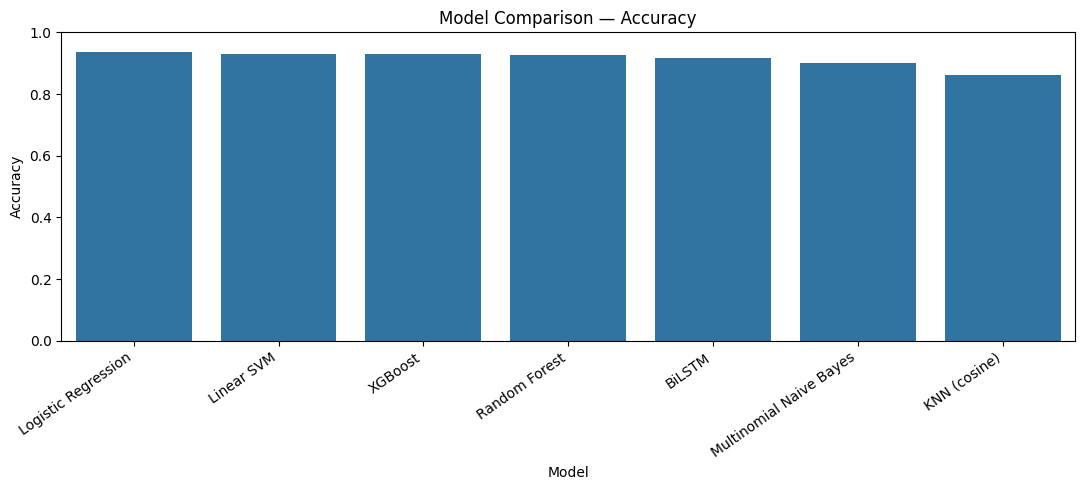

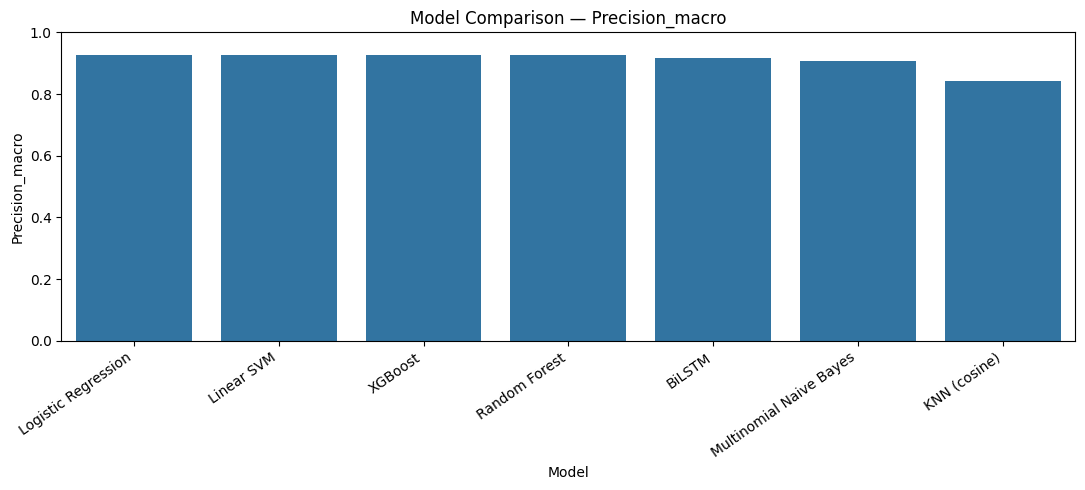

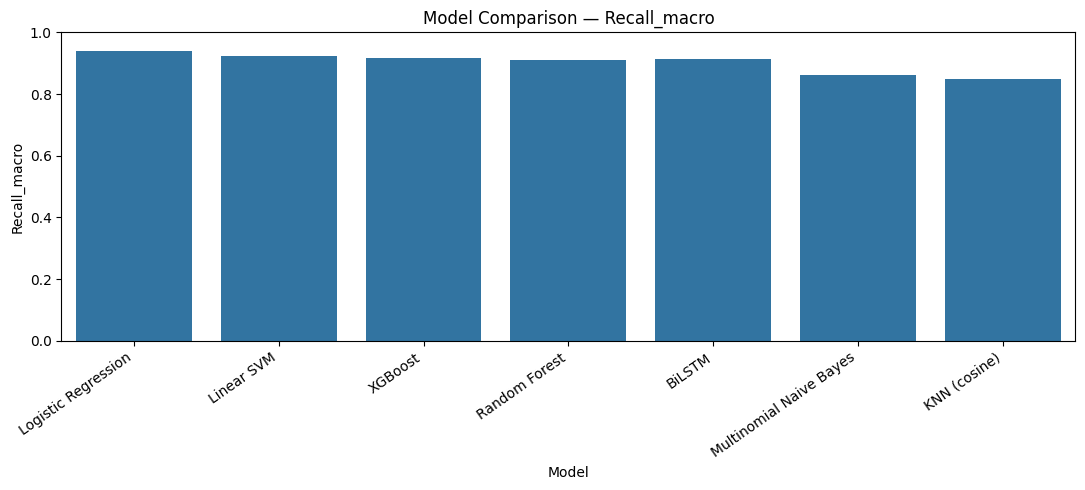

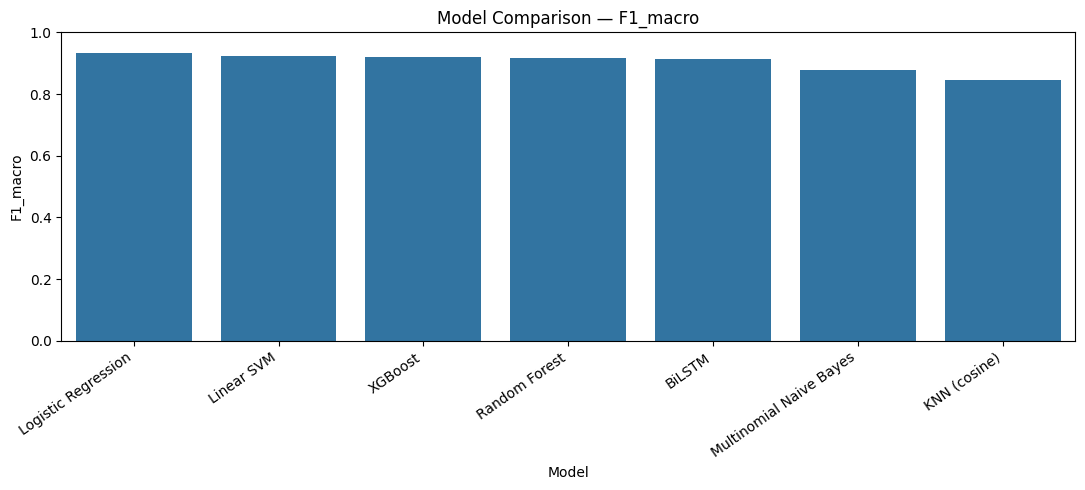

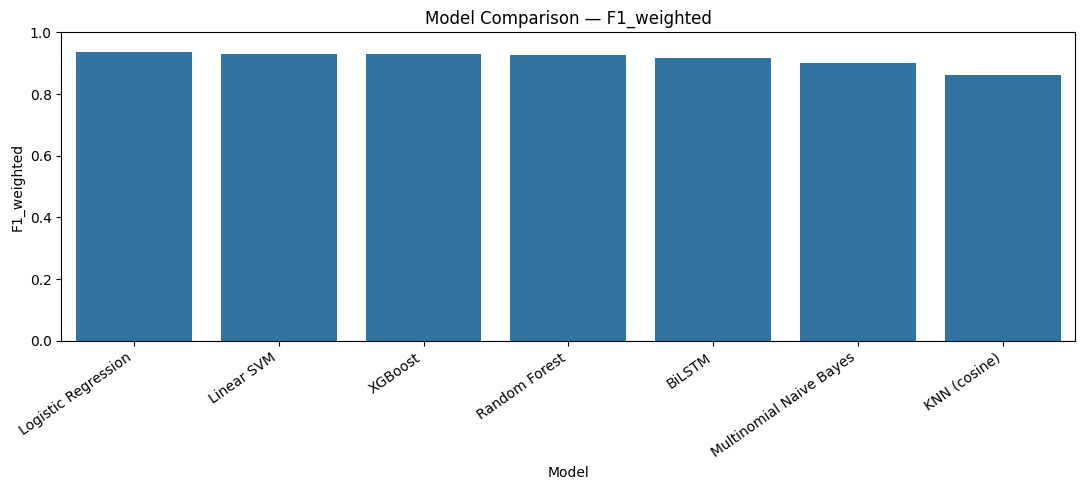

In [ ]:
# 10. Compare evaluation metrics visually
metrics_to_plot = ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro", "F1_weighted"]

for metric in metrics_to_plot:
    plt.figure(figsize=(11, 5))
    sns.barplot(data=results_df, x="Model", y=metric)
    plt.title(f"Model Comparison — {metric}")
    plt.ylabel(metric)
    plt.xlabel("Model")
    plt.xticks(rotation=35, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()


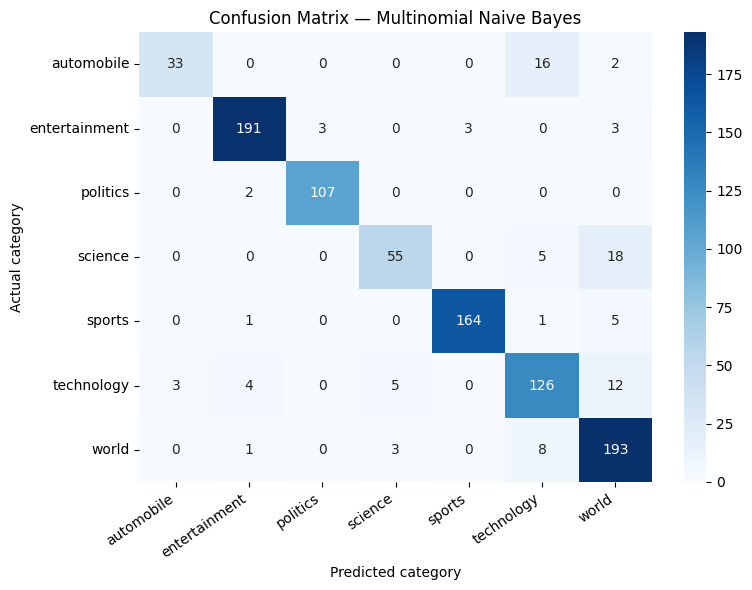

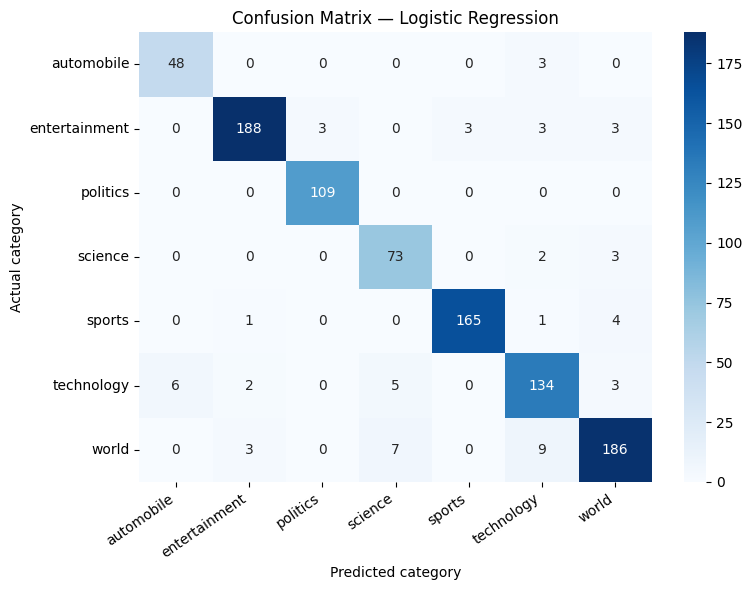

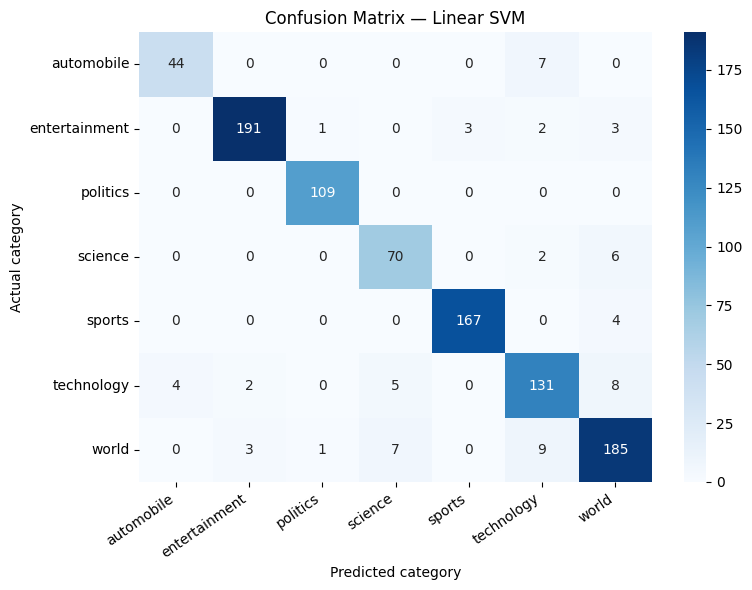

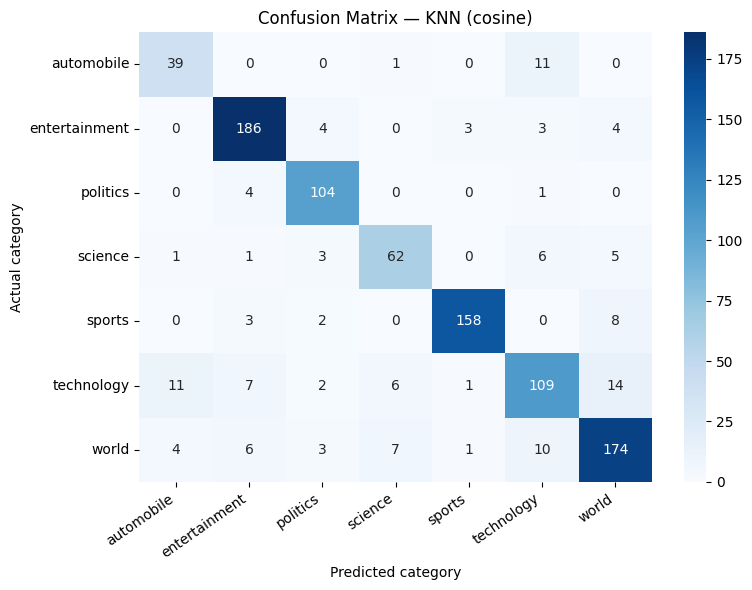

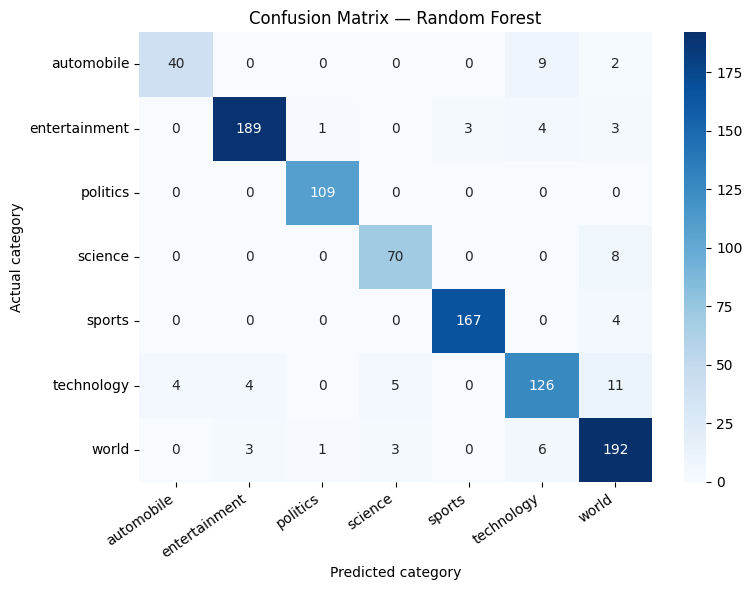

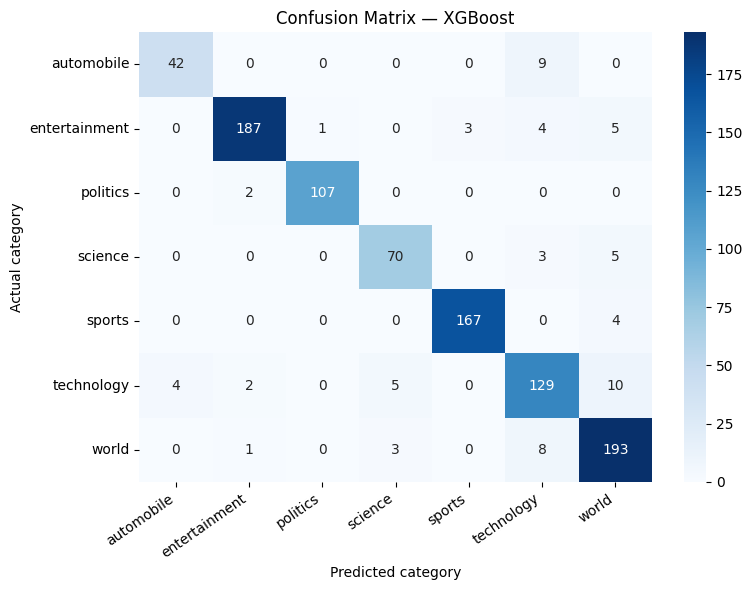

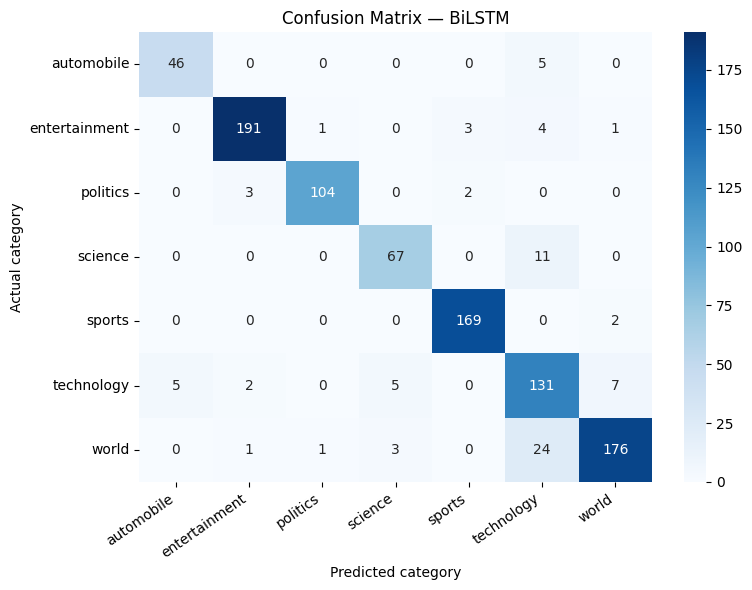

In [ ]:
# 11. Confusion matrix for every model
for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted category")
    plt.ylabel("Actual category")
    plt.xticks(rotation=35, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


In [ ]:
# 12. Per-class performance comparison (classification report)
per_class_rows = []

for name, y_pred in predictions.items():
    report = classification_report(
        y_test, y_pred, target_names=class_names,
        output_dict=True, zero_division=0
    )
    for category in class_names:
        per_class_rows.append({
            "Model": name,
            "Category": category,
            "Precision": report[category]["precision"],
            "Recall": report[category]["recall"],
            "F1-score": report[category]["f1-score"],
            "Support": report[category]["support"]
        })

per_class_df = pd.DataFrame(per_class_rows)
display(per_class_df.round(4))
per_class_df.to_csv("news_per_class_results.csv", index=False)


,Model,Category,Precision,Recall,F1-score,Support
0,Multinomial Naive Bayes,automobile,0.9167,0.6471,0.7586,51.0
1,Multinomial Naive Bayes,entertainment,0.9598,0.9550,0.9574,200.0
2,Multinomial Naive Bayes,politics,0.9727,0.9817,0.9772,109.0
3,Multinomial Naive Bayes,science,0.8730,0.7051,0.7801,78.0
4,Multinomial Naive Bayes,sports,0.9820,0.9591,0.9704,171.0
5,Multinomial Naive Bayes,technology,0.8077,0.8400,0.8235,150.0
6,Multinomial Naive Bayes,world,0.8283,0.9415,0.8813,205.0
7,Logistic Regression,automobile,0.8889,0.9412,0.9143,51.0
8,Logistic Regression,entertainment,0.9691,0.9400,0.9543,200.0
9,Logistic Regression,politics,0.9732,1.0000,0.9864,109.0


## Part D — Predict a New News Article

Use the trained model to predict a category for a new headline/article. Select any trained model by name.

In [ ]:
# 13. Test a custom news article
def predict_news_category(headline, article, model_name="Linear SVM"):
    text = (str(headline) + " " + str(article)).strip()

    if model_name == "BiLSTM":
        seq = tokenizer.texts_to_sequences([text])
        padded = pad_sequences(seq, maxlen=MAX_LEN, padding="post", truncating="post")
        probs = lstm_model.predict(padded, verbose=0)[0]
        pred_id = int(np.argmax(probs))
        confidence = float(probs[pred_id])
    else:
        model = trained_models[model_name]
        pred_id = int(model.predict([text])[0])
        confidence = None
        if hasattr(model.named_steps["model"], "predict_proba"):
            confidence = float(np.max(model.predict_proba([text])[0]))

    category = label_encoder.inverse_transform([pred_id])[0]
    print("Predicted category:", category)
    if confidence is not None:
        print(f"Model score (probability where available): {confidence:.4f}")
    return category

# Example — replace with your own article
predict_news_category(
    "India launches a new satellite",
    "The space agency announced the successful launch of a new satellite for communications and research.",
    model_name="Linear SVM"
)


Predicted category: science


'science'

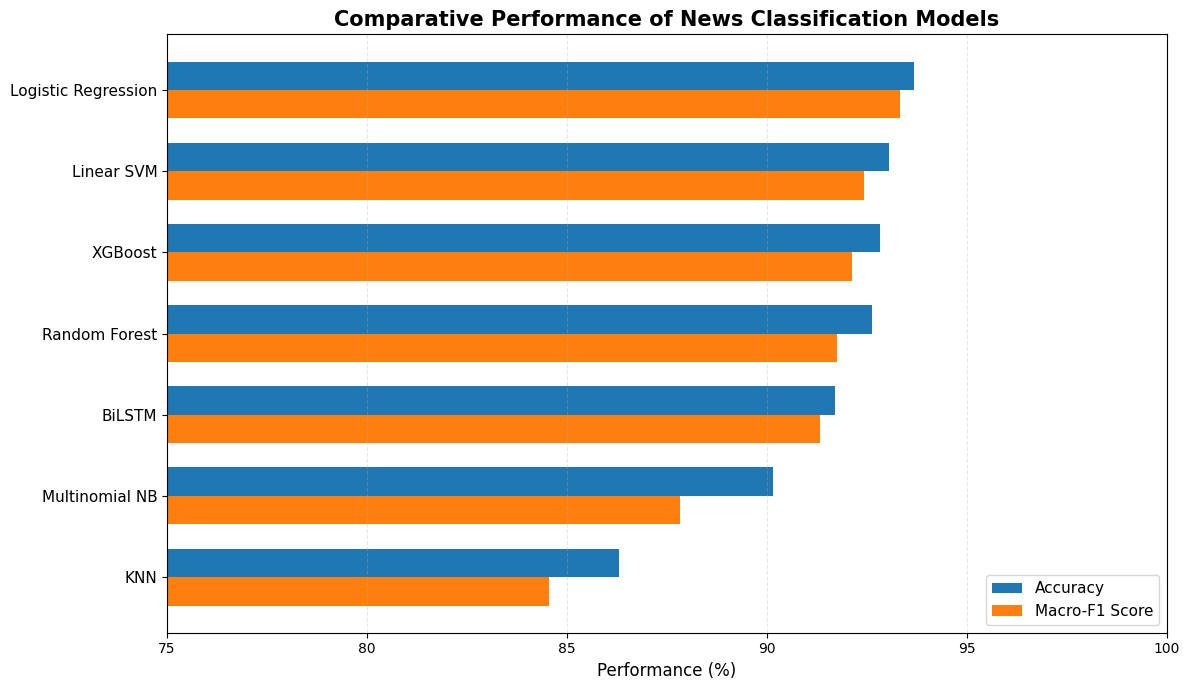

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Models
models = [
    "Logistic Regression",
    "Linear SVM",
    "XGBoost",
    "Random Forest",
    "BiLSTM",
    "Multinomial NB",
    "KNN"
]

# Actual results (in percentage)
accuracy = [93.67, 93.05, 92.84, 92.63, 91.70, 90.15, 86.31]

macro_f1 = [93.32, 92.42, 92.13, 91.75, 91.34, 87.84, 84.54]

# Plot
y = np.arange(len(models))
height = 0.35

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    y - height/2,
    accuracy,
    height,
    label="Accuracy"
)

ax.barh(
    y + height/2,
    macro_f1,
    height,
    label="Macro-F1 Score"
)

# Labels
ax.set_yticks(y)
ax.set_yticklabels(models, fontsize=11)
ax.invert_yaxis()

ax.set_xlabel("Performance (%)", fontsize=12)

ax.set_title(
    "Comparative Performance of News Classification Models",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlim(75, 100)

ax.grid(axis="x", linestyle="--", alpha=0.3)

ax.legend(loc="lower right", fontsize=11)

plt.tight_layout()

# Save high-resolution image
plt.savefig(
    "comparative_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()